In [29]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np

sys.path.append('../../')
from utils_plots import (
    apply_plot_style,
    get_layers,
    load_ii_curves,
    _min_token_length,
)

colors, markers, _linestyles = apply_plot_style()

sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths

depths = get_model_depths()


In [30]:
model = 'deepseek'
_model = 'deepseek'

# model = 'llama'
# _model = 'llama8b'

mask = 2
n_files = 500
batch_shuffle = 0
aux_A = 'source'
aux_B = 'target'
k_II = 10
avg_tokens = 1
n_tokens = 20
Nbits = 0
seeds = list(range(5))

LABEL_FONTSIZE = 17
TICK_FONTSIZE = 15
LEGEND_FONTSIZE = 13


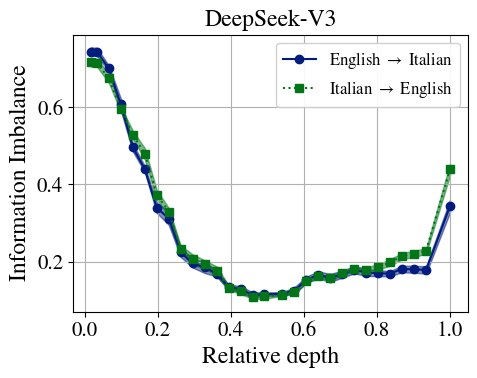

In [31]:
# Same as the last plotting layer in english-pivot.ipynb
languageA, languageB = 'english', 'italian'

# Use the shared project palette from apply_plot_style()
blue = colors[0]
red = colors[1]

label_forward = f"{languageA.capitalize()} $\\rightarrow$ {languageB.capitalize()}"
label_reciprocal = f"{languageB.capitalize()} $\\rightarrow$ {languageA.capitalize()}"
out_path = '../results/figs/english-pivot-italian-only.pdf'

mean_ii, std_ii = load_ii_curves(
    base='../results/santiago/',
    batch_shuffle=batch_shuffle,
    model=model,
    aux_A=aux_A,
    aux_B=aux_B,
    n_files=n_files,
    min_token_length=_min_token_length(model, languageA, languageB),
    languageA=languageA,
    languageB=languageB,
    mask=mask,
    k=k_II,
    Nbits=Nbits,
    seeds=seeds,
    n_tokens=n_tokens,
    avg_tokens=avg_tokens,
)

layers = get_layers(_model, depths)
x = layers / depths[_model]

fig, ax = plt.subplots(1, 1, figsize=(5, 4))

# English <-> Italian
ax.plot(
    x,
    mean_ii[0],
    label=label_forward,
    linestyle='-',
    marker='o',
    color=blue,
)
ax.fill_between(x, mean_ii[0] - std_ii[0], mean_ii[0] + std_ii[0], color=blue, alpha=0.5)

ax.plot(
    x,
    mean_ii[1],
    label=label_reciprocal,
    linestyle='dotted',
    marker='s',
    color=red,
)
ax.fill_between(x, mean_ii[1] - std_ii[1], mean_ii[1] + std_ii[1], color=red, alpha=0.5)

ax.set_title('DeepSeek-V3', fontsize=LABEL_FONTSIZE)
ax.set_xlabel('Relative depth', fontsize=LABEL_FONTSIZE)
ax.set_ylabel('Information Imbalance', fontsize=LABEL_FONTSIZE)
ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
ax.grid()
ax.legend(loc='best', fontsize=LEGEND_FONTSIZE - 1, framealpha=0.9)

fig.tight_layout()
fig.savefig(out_path, bbox_inches='tight')
plt.show()


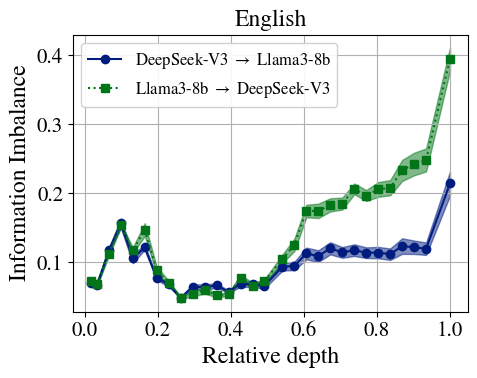

In [32]:
matched_path = 'plot-data/ds_vs_llama_matched_depth_english_hungarian_source.txt'
out_path_matched = '../results/figs/ds_vs_llama_english.pdf'

matched = np.loadtxt(matched_path)
mu_ds = matched[:, 0]
std_ds = matched[:, 1]
mu_llama = matched[:, 2]
std_llama = matched[:, 3]
x_matched = x[: len(matched)]

fig, ax = plt.subplots(1, 1, figsize=(5, 4))

ax.plot(
    x_matched,
    mu_ds,
    label='DeepSeek-V3 $\\rightarrow$ Llama3-8b',
    linestyle='-',
    marker='o',
    color=blue,
)
ax.fill_between(x_matched, mu_ds - std_ds, mu_ds + std_ds, color=blue, alpha=0.5)

ax.plot(
    x_matched,
    mu_llama,
    label='Llama3-8b $\\rightarrow$ DeepSeek-V3',
    linestyle='dotted',
    marker='s',
    color=red,
)
ax.fill_between(x_matched, mu_llama - std_llama, mu_llama + std_llama, color=red, alpha=0.5)

ax.set_title('English', fontsize=LABEL_FONTSIZE)
ax.set_xlabel('Relative depth', fontsize=LABEL_FONTSIZE)
ax.set_ylabel('Information Imbalance', fontsize=LABEL_FONTSIZE)
ax.tick_params(axis='both', labelsize=TICK_FONTSIZE)
ax.grid()
ax.legend(loc='best', fontsize=LEGEND_FONTSIZE - 1, framealpha=0.9)

fig.tight_layout()
fig.savefig(out_path_matched, bbox_inches='tight')
plt.show()
